# CardioFusion-XAI — Six-dataset quality and target audit

This notebook is an **additional** audit workflow. It does not replace or modify any of the original EDA notebooks. It evaluates each dataset independently and explicitly avoids joining rows across sources.

## Scope

- Clinical / biomarker datasets: Zheen, Framingham, UCI Heart Failure and MI Complications.
- ECG: PTB-XL.
- Echocardiography: EchoNet-Dynamic.

The purpose is to verify file availability, shapes, feature types, missingness, target distributions, split structure and patient leakage where patient identifiers exist. The six datasets are independent; no patient-level multimodal cohort is constructed.

In [1]:
from pathlib import Path
import json
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_ml_service_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").is_dir() and (candidate / "config").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
        if (candidate / "ml-service" / "src").is_dir():
            return candidate / "ml-service"
    raise FileNotFoundError("Open Jupyter from the repository or ml-service directory; could not locate ml-service.")

ML_ROOT = find_ml_service_root()
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))
DATA_ROOT = ML_ROOT / "data" / "raw"
print("ML root:", ML_ROOT)
print("Raw data root:", DATA_ROOT)

ML root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service
Raw data root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\raw


## 1. Audit the four clinical / biomarker datasets

The canonical loader below performs source-specific column normalization and target identification. This is a schema audit, not model training. It does not fit imputation or scaling parameters and does not modify the raw data.

In [2]:
from src.training.biomarker_training_data import load_biomarker_source

BIOMARKER_ROOT = DATA_ROOT / "biomarkers"
BIOMARKER_SOURCES = ["zheen", "framingham", "uci_heart_failure", "mi_complications"]
biomarker_audit = []
biomarker_target_audit = []
loaded_biomarker_data = {}

for source in BIOMARKER_SOURCES:
    try:
        data = load_biomarker_source(BIOMARKER_ROOT, source)
        loaded_biomarker_data[source] = data
        features = data.features.replace([np.inf, -np.inf], np.nan)
        biomarker_audit.append({
            "dataset": source,
            "rows": int(features.shape[0]),
            "features": int(features.shape[1]),
            "total_missing_cells": int(features.isna().sum().sum()),
            "missing_cell_percent": float(features.isna().mean().mean() * 100),
            "duplicate_feature_rows": int(features.duplicated().sum()),
            "targets": ", ".join(data.targets),
            "status": "loaded",
        })
        for target, series in data.targets.items():
            counts = series.value_counts(dropna=False).sort_index()
            for label, count in counts.items():
                biomarker_target_audit.append({
                    "dataset": source,
                    "target": target,
                    "label": str(label),
                    "count": int(count),
                    "proportion": float(count / len(series)),
                })
    except Exception as exc:
        biomarker_audit.append({"dataset": source, "status": "not_available_or_schema_mismatch", "reason": f"{type(exc).__name__}: {exc}"})

biomarker_summary = pd.DataFrame(biomarker_audit)
target_summary = pd.DataFrame(biomarker_target_audit)
display(biomarker_summary)
display(target_summary.head(100))

,dataset,rows,features,total_missing_cells,missing_cell_percent,duplicate_feature_rows,targets,status
0,zheen,1319,8,0,0.000000,0,acute_mi,loaded
1,framingham,4240,15,645,1.014151,0,ten_year_chd_risk,loaded
2,uci_heart_failure,299,11,0,0.000000,0,hf_mortality,loaded
3,mi_complications,1700,107,10486,5.764706,0,"fibr_preds, preds_tah, jelud_tah, fibr_jelud, ...",loaded


,dataset,target,label,count,proportion
0,zheen,acute_mi,0.0,509,0.385898
1,zheen,acute_mi,1.0,810,0.614102
2,framingham,ten_year_chd_risk,0.0,3596,0.848113
3,framingham,ten_year_chd_risk,1.0,644,0.151887
4,uci_heart_failure,hf_mortality,0.0,203,0.678930
5,uci_heart_failure,hf_mortality,1.0,96,0.321070
6,mi_complications,fibr_preds,0.0,1530,0.900000
7,mi_complications,fibr_preds,1.0,170,0.100000
8,mi_complications,preds_tah,0.0,1680,0.988235
9,mi_complications,preds_tah,1.0,20,0.011765


## 2. Audit PTB-XL preprocessing manifest

This checks the already-preprocessed manifest expected by the ECG training notebooks. It verifies split presence and patient disjointness. It does not load or train on signals.

In [3]:
PTBXL_VERSION = "100hz_record_zscore"
ptbxl_manifest = ML_ROOT / "data" / "processed" / "ecg" / "ptbxl" / PTBXL_VERSION / "manifests" / "ptbxl_manifest.csv"

if ptbxl_manifest.is_file():
    ecg_df = pd.read_csv(ptbxl_manifest)
    required = {"split", "patient_id", "processed_path", "ecg_id"}
    missing = sorted(required - set(ecg_df.columns))
    if missing:
        raise ValueError(f"PTB-XL manifest missing required columns: {missing}")
    print("PTB-XL rows:", len(ecg_df))
    display(ecg_df["split"].value_counts(dropna=False).rename_axis("split").to_frame("records"))
    patient_sets = {name: set(ecg_df.loc[ecg_df["split"] == name, "patient_id"].dropna()) for name in ["train", "val", "test"]}
    overlap = {
        "train_val": len(patient_sets["train"] & patient_sets["val"]),
        "train_test": len(patient_sets["train"] & patient_sets["test"]),
        "val_test": len(patient_sets["val"] & patient_sets["test"]),
    }
    print("Patient overlap (all must be zero):", overlap)
    if any(overlap.values()):
        raise RuntimeError("Patient leakage detected in the PTB-XL manifest.")
    label_cols = [c for c in ["NORM", "MI", "STTC", "CD", "HYP"] if c in ecg_df.columns]
    if label_cols:
        display(ecg_df[label_cols].apply(pd.to_numeric, errors="coerce").mean().rename("positive_fraction").to_frame())
else:
    print("PTB-XL processed manifest not found:", ptbxl_manifest)
    print("Run the existing notebooks/02_preprocessing/02_ptbxl_ecg_preprocessing.ipynb first.")

PTB-XL rows: 21837


,records
split,
train,17441
test,2203
val,2193


Patient overlap (all must be zero): {'train_val': 0, 'train_test': 0, 'val_test': 0}


,positive_fraction
NORM,0.436324
MI,0.251225
STTC,0.240418
CD,0.224710
HYP,0.121583


## 3. Audit EchoNet-Dynamic source metadata / manifest

EchoNet is audited separately. No matching with PTB-XL or biomarker records is attempted.

Echo metadata: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\processed\echo\echonet\echonet_panecho_manifest.csv
Rows: 1530 Columns: 7


,video_name,video_path,EF,EDV,ESV,num_frames,split
0,0X100009310A3BD7FC,data/raw/echo/echonet/Videos/0X100009310A3BD7F...,78.498406,69.210534,14.881368,174,val
1,0X1002E8FBACD08477,data/raw/echo/echonet/Videos/0X1002E8FBACD0847...,59.101988,98.742884,40.383876,215,train
2,0X1005D03EED19C65B,data/raw/echo/echonet/Videos/0X1005D03EED19C65...,62.363798,37.909734,14.267784,104,train
3,0X10075961BC11C88E,data/raw/echo/echonet/Videos/0X10075961BC11C88...,54.545097,72.914210,33.143084,122,train
4,0X10094BA0A028EAC3,data/raw/echo/echonet/Videos/0X10094BA0A028EAC...,24.887742,169.855024,127.581945,207,val


,videos
split,
train,1144
val,204
test,182


,EF
count,1530.000000
mean,56.283676
std,12.133747
min,6.907258
25%,52.533759
50%,59.417450
75%,64.278103
max,88.142061


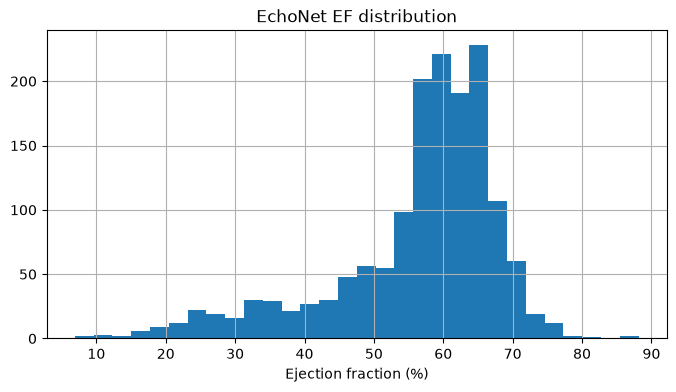

In [4]:
ECHO_RAW = DATA_ROOT / "echo" / "echonet"
echo_candidates = [
    ML_ROOT / "data" / "processed" / "echo" / "echonet" / "echonet_panecho_manifest.csv",
    ECHO_RAW / "FileList.csv",
]
echo_file = next((p for p in echo_candidates if p.is_file()), None)
if echo_file is None:
    print("EchoNet FileList/processed manifest not found. Expected one of:")
    for p in echo_candidates: print(" -", p)
else:
    echo_df = pd.read_csv(echo_file)
    print("Echo metadata:", echo_file)
    print("Rows:", len(echo_df), "Columns:", len(echo_df.columns))
    display(echo_df.head())
    possible_split = next((c for c in ["split", "Split"] if c in echo_df.columns), None)
    if possible_split:
        display(echo_df[possible_split].value_counts(dropna=False).rename_axis("split").to_frame("videos"))
    ef_col = next((c for c in ["EF", "ef"] if c in echo_df.columns), None)
    if ef_col:
        ef = pd.to_numeric(echo_df[ef_col], errors="coerce")
        display(ef.describe().to_frame("EF"))
        ax = ef.dropna().hist(bins=30, figsize=(8, 4))
        ax.set_title("EchoNet EF distribution")
        ax.set_xlabel("Ejection fraction (%)")
        plt.show()

## 4. Dataset and target interpretation checks

Use this checklist before training. A model's target must retain its original endpoint meaning; the same numeric code in two datasets does not imply the same clinical event.

| Dataset | Target meaning | Important restriction |
|---|---|---|
| Zheen | Dataset-defined heart-attack class | Not a universal acute-MI probability |
| Framingham | 10-year CHD outcome | Long-term risk task, not acute MI |
| UCI Heart Failure | Death event during follow-up | Existing-HF cohort only; never incident HF screening |
| MI Complications | Post-MI complications | Prior MI population only; exclude post-outcome leakage |
| PTB-XL | ECG diagnostic/rhythm annotations | Multi-label ECG findings, not necessarily confirmed diagnoses |
| EchoNet-Dynamic | LVEF measurement | Continuous measurement, not disease probability |

No cross-dataset patient join is performed in this notebook.

In [5]:
AUDIT_DIR = ML_ROOT / "artifacts" / "eda" / "six_dataset_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
biomarker_summary.to_csv(AUDIT_DIR / "biomarker_dataset_summary.csv", index=False)
target_summary.to_csv(AUDIT_DIR / "biomarker_target_distribution.csv", index=False)
run_metadata = {
    "biomarker_sources_loaded": list(loaded_biomarker_data),
    "ptbxl_manifest_found": bool(ptbxl_manifest.is_file()),
    "echo_manifest_or_filelist": str(echo_file) if echo_file else None,
    "dataset_pairing": "independent datasets; no patient-level cross-modal pairing",
}
(AUDIT_DIR / "audit_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
print("Audit artifacts saved to:", AUDIT_DIR)

Audit artifacts saved to: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\artifacts\eda\six_dataset_audit
